# Дополнительное задание: прогнозирование временного ряда через регрессию

**Датасет:** Air Passengers — месячное число авиапассажиров, 1949–1960 (144 наблюдения).
**Целевая переменная:** `passengers`. Модель обучается на `log(passengers)`, метрики считаются на исходной шкале.

**План:** загрузка и визуализация → признаки только из прошлого → разделение по времени и кросс-валидация → модели (1 шаг) → стратегии на горизонт H=12 → метрики и анализ ошибок → STL-декомпозиция и проверка STL-признаков → выводы.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
RANDOM_STATE = 42

## 1. Загрузка данных
Дата собирается из года и названия месяца, приводится к `datetime`, ряд сортируется по времени и получает месячную частоту (`MS`).

In [2]:
# Датасет Air Passengers (месячное число авиапассажиров, 1949-1960)
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv"
try:
    raw = pd.read_csv(URL)
except Exception:
    raw = pd.read_csv("flights.csv")      # локальная копия, если нет интернета

raw["date"] = pd.to_datetime(raw["year"].astype(str) + "-" + raw["month"].astype(str) + "-01",
                             format="%Y-%B-%d")
raw = raw.sort_values("date").reset_index(drop=True)

y = raw.set_index("date")["passengers"].astype(float).asfreq("MS")
print("Период:", y.index.min().date(), "-", y.index.max().date(), "| наблюдений:", len(y),
      "| пропусков:", int(y.isna().sum()))
display(y.head())
display(y.describe().round(1).to_frame("passengers").T)

Период: 1949-01-01 - 1960-12-01 | наблюдений: 144 | пропусков: 0


date
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: passengers, dtype: float64

,count,mean,std,min,25%,50%,75%,max
passengers,144.0,280.3,120.0,104.0,180.0,265.5,360.5,622.0


## 2. Визуализация ряда

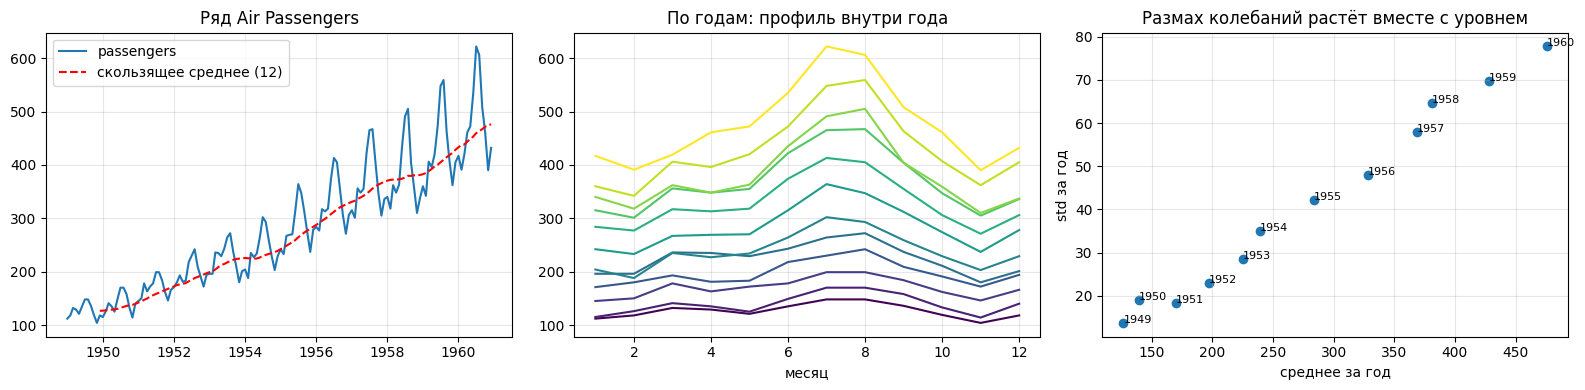

Корреляция mean-std по годам: 0.994


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1) ряд и скользящее среднее за 12 месяцев
axes[0].plot(y, label="passengers")
axes[0].plot(y.rolling(12).mean(), "r--", label="скользящее среднее (12)")
axes[0].set_title("Ряд Air Passengers"); axes[0].legend()

# 2) сезонный график: каждая линия - один год
pivot = y.to_frame("v").assign(year=y.index.year, month=y.index.month).pivot(index="month", columns="year", values="v")
pivot.plot(ax=axes[1], colormap="viridis", legend=False)
axes[1].set_title("По годам: профиль внутри года"); axes[1].set_xlabel("месяц")

# 3) среднее и стд. отклонение по годам -> гетероскедастичность
g = y.groupby(y.index.year).agg(["mean", "std"])
axes[2].scatter(g["mean"], g["std"])
for yr, r in g.iterrows():
    axes[2].annotate(str(yr), (r["mean"], r["std"]), fontsize=8)
axes[2].set_xlabel("среднее за год"); axes[2].set_ylabel("std за год")
axes[2].set_title("Размах колебаний растёт вместе с уровнем")
plt.tight_layout(); plt.show()

print("Корреляция mean-std по годам: %.3f" % g["mean"].corr(g["std"]))

### Выводы по визуализации

- **Тренд:** есть, устойчивый и восходящий. Среднегодовое значение выросло примерно с 127 до 476 тыс. пассажиров.
- **Сезонность:** годовая (период 12 месяцев), чёткая. Пик приходится на июль–август, минимум на ноябрь. Профили разных лет почти параллельны. Суточной и недельной сезонности нет: данные месячные.
- **Гетероскедастичность:** размах сезонных колебаний растёт вместе с уровнем (корреляция среднего и std по годам 0.99). Это мультипликативная сезонность, поэтому далее используется `log(y)`: после логарифма сезонность становится аддитивной, а ошибки в процентах примерно постоянны.
- **Выбросы:** грубых выбросов нет. По остатку STL лишь несколько умеренных отклонений (|z|>3) в 1951–1954 годах, это не аномалии, а шум.

Ниже описательная STL-декомпозиция по всему ряду. Она нужна только для анализа: в признаки идёт отдельная версия, построенная только по прошлому (см. раздел 8).

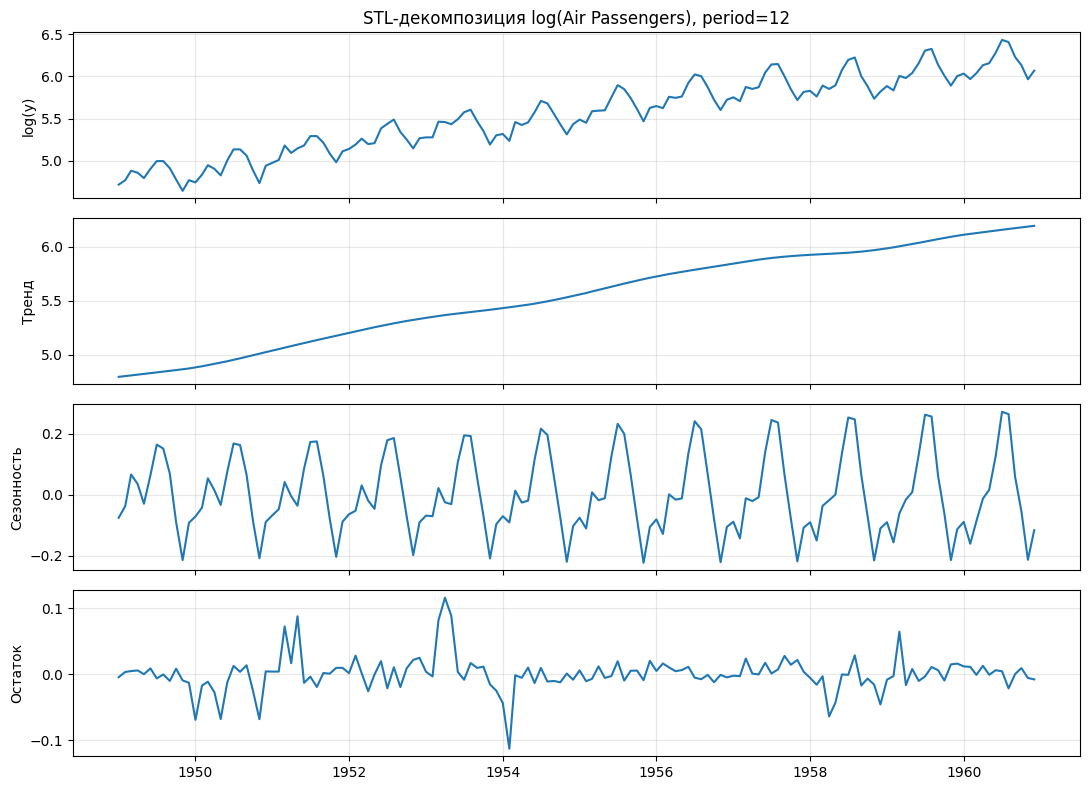

Доля дисперсии log(y), объяснённая трендом+сезонностью: 0.9964
Размах сезонной компоненты (в log): 0.495  -> пик/впадина = x1.64
Выбросы по остатку STL (|z|>3): ['1951-05', '1953-03', '1953-04', '1953-05', '1954-02']
Топ-3 по |z|: [('1953-04', 4.35), ('1954-02', 4.28), ('1953-05', 3.32)]


In [4]:
# Лог-преобразование: делает сезонность примерно аддитивной (мультипликативная -> аддитивная)
logy = np.log(y.values)
dates = y.index

# Описательная STL-декомпозиция по ВСЕМУ ряду (только для анализа, в признаки не идёт - там была бы утечка)
stl_full = STL(pd.Series(logy, index=dates), period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (name, comp) in zip(axes, [("log(y)", stl_full.observed), ("Тренд", stl_full.trend),
                                   ("Сезонность", stl_full.seasonal), ("Остаток", stl_full.resid)]):
    ax.plot(comp); ax.set_ylabel(name)
axes[0].set_title("STL-декомпозиция log(Air Passengers), period=12")
plt.tight_layout(); plt.show()

resid = stl_full.resid
z = (resid - resid.mean()) / resid.std()
out = z[np.abs(z) > 3]
print("Доля дисперсии log(y), объяснённая трендом+сезонностью: %.4f" % (1 - resid.var() / stl_full.observed.var()))
print("Размах сезонной компоненты (в log): %.3f  -> пик/впадина = x%.2f" %
      (stl_full.seasonal.max() - stl_full.seasonal.min(), np.exp(stl_full.seasonal.max() - stl_full.seasonal.min())))
print("Выбросы по остатку STL (|z|>3):", "нет" if out.empty else list(out.index.strftime("%Y-%m")))
print("Топ-3 по |z|:", [(d.strftime("%Y-%m"), round(v, 2)) for d, v in z.abs().nlargest(3).items()])

## 3. Признаки (только из прошлого)

Для момента `t` известны значения до `y_t` включительно, прогнозируется `y_{t+h}`.

| Группа | Признаки |
|---|---|
| Лаги | `lag_0 … lag_11` (`y_t … y_{t-11}`), p = 12 |
| Скользящие статистики | среднее, медиана, std, min, max по окнам 3, 6, 12 (окно заканчивается на `y_t`) |
| Сезонные | `lag_11` — значение того же месяца год назад (для h=1); `diff_12` — годовой прирост |
| Календарные | месяц, sin/cos месяца, квартал, год, индекс времени, флаг сезона отпусков (июль–август). Календарь целевого месяца известен заранее |
| STL (отдельный набор) | тренд на момент `t`, наклон тренда, сезонность целевого месяца. STL подгоняется по истории до `t`, будущее не используется |

День недели, час и выходные/праздники для месячных данных неприменимы. Их роль играют месяц и флаг сезона отпусков.

**Защита от утечки:** все признаки считаются по `logy[:t+1]`. Для каждой точки отсчёта STL пересчитывается заново и видит только прошлое.

In [5]:
P = 12                 # число лагов (y_t, y_t-1, ..., y_t-11) - покрывает годовую сезонность
WINDOWS = (3, 6, 12)   # окна для скользящих статистик
H = 12                 # горизонт прогноза (месяцев)

def date_of(s):
    """Дата наблюдения с индексом s (работает и для будущих, ещё не наблюдённых точек)."""
    return dates[0] + pd.DateOffset(months=int(s))

def origin_features(arr):
    """Признаки, построенные ТОЛЬКО по истории arr (последний элемент = момент t)."""
    f = {f"lag_{k}": arr[-1 - k] for k in range(P)}              # лаги: lag_0 = y_t, lag_11 = y_{t-11}
    for w in WINDOWS:                                            # скользящие статистики за окно w (включая y_t)
        win = arr[-w:]
        f[f"roll_mean_{w}"] = win.mean()
        f[f"roll_median_{w}"] = np.median(win)
        f[f"roll_std_{w}"] = win.std(ddof=1)
        f[f"roll_min_{w}"] = win.min()
        f[f"roll_max_{w}"] = win.max()
    f["diff_1"] = arr[-1] - arr[-2]                              # последний прирост
    f["diff_12"] = arr[-1] - arr[-13]                            # годовой прирост (y_t - y_{t-12})
    return f

def calendar_features(s):
    """Календарные признаки целевого месяца s (дата известна заранее - утечки нет)."""
    d = date_of(s); m = d.month
    return {"month": m, "month_sin": np.sin(2 * np.pi * m / 12), "month_cos": np.cos(2 * np.pi * m / 12),
            "quarter": d.quarter, "year": d.year, "time_idx": s,
            "is_summer_peak": int(m in (7, 8))}   # праздники/выходные для месячных данных неприменимы -> сезон отпусков

def stl_info(arr):
    """STL по истории arr (без будущего): последнее значение тренда, наклон тренда и сезонность последних 12 месяцев."""
    res = STL(pd.Series(arr), period=12, robust=True).fit()
    tr, se = res.trend.values, res.seasonal.values
    return tr[-1], tr[-1] - tr[-4], se[-12:]

def make_features(arr, h, use_stl=True, stl=None):
    """Строка признаков: история до t = len(arr)-1, прогнозируем y_{t+h}."""
    t = len(arr) - 1
    f = origin_features(arr)
    f.update(calendar_features(t + h))
    if use_stl:
        tl, ts, se = stl if stl is not None else stl_info(arr)
        f.update(stl_trend_last=tl, stl_trend_slope=ts, stl_seas_target=se[h - 1])  # se[h-1] = сезонность месяца t+h год назад
    return f

# Индекс границы: последние 24 месяца - тест
N = len(logy)
TEST_SIZE = 24
TRAIN_END = N - TEST_SIZE - 1          # индекс последней обучающей точки
T_MIN = 23                             # STL требует >= 2 полных сезонов истории
STL_CACHE = {t: stl_info(logy[: t + 1]) for t in range(T_MIN, N - 1)}   # STL для каждой точки отсчёта - только по прошлому

def build_xy(h, origins, use_stl=True):
    rows = [make_features(logy[: t + 1], h, use_stl, STL_CACHE[t] if use_stl else None) for t in origins]
    X = pd.DataFrame(rows, index=[date_of(t + h) for t in origins])   # индекс = дата целевого месяца
    return X, pd.Series(logy[[t + h for t in origins]], index=X.index)

# Одношаговая задача (h=1): train - цели до TRAIN_END, test - последние 24 месяца
tr_orig = list(range(T_MIN, TRAIN_END))               # цели t+1 <= TRAIN_END
te_orig = list(range(TRAIN_END, N - 1))               # цели t+1 в тестовом периоде
X_tr, y_tr = build_xy(1, tr_orig); X_te, y_te = build_xy(1, te_orig)
X_tr_b, _ = build_xy(1, tr_orig, use_stl=False); X_te_b, _ = build_xy(1, te_orig, use_stl=False)

print("Train: %s .. %s (%d строк) | Test: %s .. %s (%d строк)" % (
    X_tr.index[0].date(), X_tr.index[-1].date(), len(X_tr), X_te.index[0].date(), X_te.index[-1].date(), len(X_te)))
print("Признаков без STL:", X_tr_b.shape[1], "| с STL:", X_tr.shape[1])
display(X_tr.iloc[:3, :8].round(3))

Train: 1951-01-01 .. 1958-12-01 (96 строк) | Test: 1959-01-01 .. 1960-12-01 (24 строк)
Признаков без STL: 36 | с STL: 39


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
1951-01-01,4.942,4.736,4.890,5.063,5.136,5.136,5.004,4.828
1951-02-01,4.977,4.942,4.736,4.890,5.063,5.136,5.136,5.004
1951-03-01,5.011,4.977,4.942,4.736,4.890,5.063,5.136,5.136


## 4. Разбиение по времени и кросс-валидация

- **Train:** 1951-01 … 1958-12 (первые строки отброшены: нужна история для лагов и STL), **test:** последние 24 месяца (1959–1960), без перемешивания.
- **CV:** `TimeSeriesSplit` с расширяющимся окном, 4 фолда, валидация — следующие 12 месяцев (полный сезон). Гиперпараметры Ridge/Lasso подбираются внутри каждого фолда (вложенная CV), поэтому оценка не «подглядывает» в валидацию.
- **Бейзлайны:** наивный (`y_t`) и сезонный наивный (значение год назад).
- **Метрики:** MSE, MAE, MAPE, WAPE на исходной шкале.

In [6]:
def metrics(y_true, y_pred):
    """Метрики на ИСХОДНОЙ шкале (пассажиры), на вход - значения уже после exp."""
    e = y_true - y_pred
    return {"MSE": np.mean(e ** 2), "MAE": np.mean(np.abs(e)),
            "MAPE, %": 100 * np.mean(np.abs(e / y_true)),
            "WAPE, %": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y_true))}

def make_models():
    return {
        "LinearRegression": Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
        "Ridge": GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", Ridge())]),
                              {"m__alpha": np.logspace(-4, 2, 13)}, cv=TimeSeriesSplit(3),
                              scoring="neg_mean_squared_error"),
        "Lasso": GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", Lasso(max_iter=100000))]),
                              {"m__alpha": np.logspace(-6, -1, 11)}, cv=TimeSeriesSplit(3),
                              scoring="neg_mean_squared_error"),
        "GradientBoosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2,
                                                      subsample=0.8, random_state=RANDOM_STATE),
    }

# Расширяющееся окно: 4 фолда, валидация = следующие 12 месяцев (полный сезон)
cv = TimeSeriesSplit(n_splits=4, test_size=12)
print("Схема CV (расширяющееся окно), размеры train/val по фолдам:")
for i, (a, b) in enumerate(cv.split(X_tr)):
    print(f"  fold {i+1}: train {X_tr.index[a[0]].strftime('%Y-%m')}..{X_tr.index[a[-1]].strftime('%Y-%m')} ({len(a)})"
          f" -> val {X_tr.index[b[0]].strftime('%Y-%m')}..{X_tr.index[b[-1]].strftime('%Y-%m')} ({len(b)})")

def cv_scores(model, X, y):
    res = []
    for a, b in cv.split(X):
        m = clone(model).fit(X.iloc[a], y.iloc[a])
        res.append(metrics(np.exp(y.iloc[b]), np.exp(m.predict(X.iloc[b]))))
    return pd.DataFrame(res).mean().to_dict()

def run_one_step(Xtr, Xte, label):
    rows, fitted = [], {}
    # бейзлайны (без обучения): наивный y_{t} и сезонный наивный y_{t-11}=тот же месяц год назад
    for name, col in [("Naive (y_t)", "lag_0"), ("Seasonal naive (год назад)", "lag_11")]:
        rows.append({"model": name, "set": "train", **metrics(np.exp(y_tr), np.exp(Xtr[col]))})
        rows.append({"model": name, "set": "test", **metrics(np.exp(y_te), np.exp(Xte[col]))})
    for name, mdl in make_models().items():
        cvs = cv_scores(mdl, Xtr, y_tr)
        mdl.fit(Xtr, y_tr); fitted[name] = mdl
        rows.append({"model": name, "set": "CV (mean)", **cvs})
        rows.append({"model": name, "set": "train", **metrics(np.exp(y_tr), np.exp(mdl.predict(Xtr)))})
        rows.append({"model": name, "set": "test", **metrics(np.exp(y_te), np.exp(mdl.predict(Xte)))})
    out = pd.DataFrame(rows).set_index(["model", "set"])
    return out, fitted

res_base, fit_base = run_one_step(X_tr_b, X_te_b, "base")
print("=== Одношаговый прогноз, признаки БЕЗ STL ===")
display(res_base.round(3))
for k in ("Ridge", "Lasso"):
    print(k, "лучший alpha:", fit_base[k].best_params_)

Схема CV (расширяющееся окно), размеры train/val по фолдам:
  fold 1: train 1951-01..1954-12 (48) -> val 1955-01..1955-12 (12)
  fold 2: train 1951-01..1955-12 (60) -> val 1956-01..1956-12 (12)
  fold 3: train 1951-01..1956-12 (72) -> val 1957-01..1957-12 (12)
  fold 4: train 1951-01..1957-12 (84) -> val 1958-01..1958-12 (12)


=== Одношаговый прогноз, признаки БЕЗ STL ===


MSE     MAE  MAPE, %  WAPE, %
model                      set                                          
Naive (y_t)                train       972.010  24.469    8.735    8.927
                           test       2681.375  44.208    9.730    9.775
Seasonal naive (год назад) train      1161.292  30.521   11.720   11.135
                           test       2498.667  47.583   10.523   10.521
LinearRegression           CV (mean)   404.014  15.403    4.430    4.611
                           train        74.347   6.462    2.382    2.358
                           test        210.017  11.988    2.720    2.651
Ridge                      CV (mean)   280.235  12.702    3.679    3.781
                           train        89.870   7.260    2.721    2.649
                           test        186.024  10.772    2.465    2.382
Lasso                      CV (mean)   326.316  14.164    4.255    4.369
                           train        83.834   7.068    2.693    2.579
                           test        180.660  10.788    2.437    2.385
GradientBoosting           CV (mean)  1237.006  27.591    7.883    8.339
                           train         5.786   1.872    0.684    0.683
                           test       3103.181  41.777    8.477    9.238

Ridge лучший alpha: {'m__alpha': np.float64(1.0)}
Lasso лучший alpha: {'m__alpha': np.float64(0.00031622776601683794)}


## 5. Одношаговая модель (h = 1)

### Результаты одношагового прогноза

- **Линейные модели с регуляризацией сильно лучше бейзлайнов.** Ridge и Lasso дают MAPE ≈ 2.4–2.5% на тесте против 9.7–10.5% у наивных прогнозов.
- **Ridge — лучший по CV** (MAPE 3.7%, MAE 12.7). У Lasso и обычной регрессии CV хуже: при 36 коррелированных признаках и 48–84 обучающих строках регуляризация помогает.
- **Train и test.** У линейных моделей ошибки близки (MAPE ≈ 2.4–2.7% на train и на test), переобучение слабое. MSE и MAE на тесте больше, чем на train, только потому что уровень ряда вырос. В процентах качество не ухудшилось. CV-ошибка выше, потому что ранние фолды обучаются на 48–60 строках.
- **GradientBoosting — явное переобучение:** MAPE 0.7% на train и 8.5% на test. Деревья не экстраполируют: в 1959–1960 значения выше всего, что было в обучении, и прогноз «упирается» в максимум train. Для ряда с трендом бустингу нужна разностная цель или детрендинг.

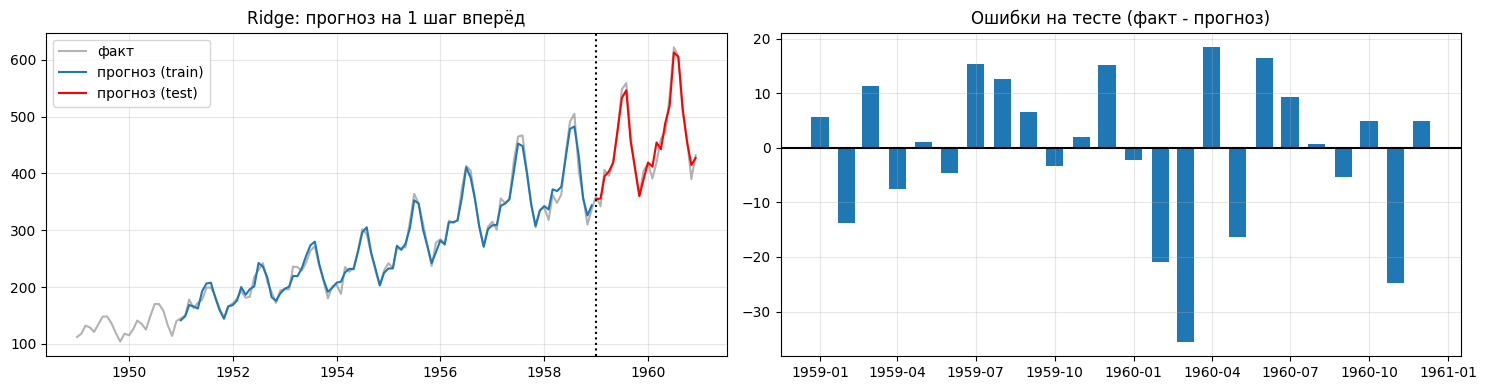

In [7]:
best = "Ridge"
pred_te = np.exp(fit_base[best].predict(X_te_b)); pred_tr = np.exp(fit_base[best].predict(X_tr_b))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(y, color="gray", alpha=0.6, label="факт")
axes[0].plot(X_tr_b.index, pred_tr, label="прогноз (train)")
axes[0].plot(X_te_b.index, pred_te, "r", label="прогноз (test)")
axes[0].axvline(X_te_b.index[0], color="k", ls=":"); axes[0].legend(); axes[0].set_title(f"{best}: прогноз на 1 шаг вперёд")

err_te = np.exp(y_te) - pred_te
axes[1].bar(X_te_b.index, err_te, width=20); axes[1].axhline(0, color="k")
axes[1].set_title("Ошибки на тесте (факт - прогноз)")
plt.tight_layout(); plt.show()

## 6. Прогноз на горизонт H = 12 шагов

От последней обучающей точки (декабрь 1958) прогнозируется весь 1959 год тремя стратегиями (модель — Ridge):

- **рекурсивная:** одношаговая модель, свои прогнозы подставляются в лаги, скользящие окна и STL;
- **прямая:** отдельная модель на каждый шаг h = 1…12;
- **гибридная:** среднее рекурсивной и прямой.

Каждый вариант считается без STL-признаков и с ними.

### Выводы
- Лучший результат у **рекурсивной стратегии без STL: MAPE 2.0%** (MAE 8.7). Гибрид — 2.7%, прямая — 4.0%, сезонный наивный прогноз — 11.1%.
- Прямая стратегия хуже, потому что на каждый горизонт обучается своя модель на меньшем числе строк (для h=12 около 85), а ошибки не копятся, но и не усредняются. Ошибка прямой выше всего на шагах 6, 8, 9 и 10 (5.6–9% против 1.2–2.9% у рекурсивной), что видно в таблице ниже.
- Оценка по одному 12-месячному окну шумная. Это сравнение стратегий на одном прогнозе, а не доказательство превосходства.

=== Прогноз на H=12 шагов (1959 г.), метрики на исходной шкале ===


,MSE,MAE,"MAPE, %","WAPE, %"
Рекурсивная (без STL),97.357,8.678,2.005,2.026
Прямая (без STL),521.641,18.083,3.985,4.222
Гибридная (без STL),235.759,12.128,2.688,2.831
Рекурсивная (с STL),286.095,15.113,3.469,3.528
Прямая (с STL),586.122,21.423,4.779,5.001
Гибридная (с STL),338.180,16.221,3.742,3.787
Seasonal naive,2426.000,47.333,11.058,11.051


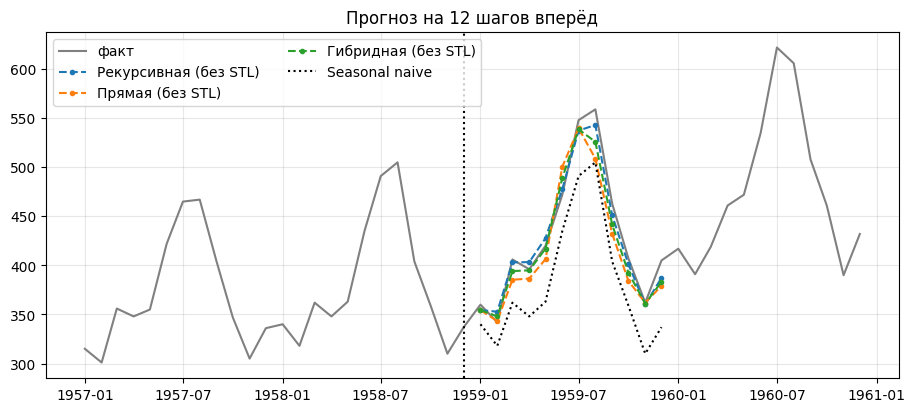

In [8]:
# ===== Многошаговый прогноз на H=12 месяцев от последней обучающей точки =====
T0 = TRAIN_END                           # прогнозируем месяцы T0+1 ... T0+12 (весь 1959 год)
actual_H = np.exp(logy[T0 + 1: T0 + H + 1])
dates_H = [date_of(T0 + h) for h in range(1, H + 1)]

def make_ridge():
    return GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", Ridge())]),
                        {"m__alpha": np.logspace(-4, 2, 13)}, cv=TimeSeriesSplit(3), scoring="neg_mean_squared_error")

def recursive_forecast(use_stl):
    Xa, ya = build_xy(1, tr_orig, use_stl)          # одношаговая модель, обучена только на train
    model = make_ridge().fit(Xa, ya)
    hist = list(logy[: T0 + 1]); preds = []
    for _ in range(H):
        arr = np.array(hist)
        row = pd.DataFrame([make_features(arr, 1, use_stl)])    # свои прогнозы идут в лаги/окна/STL
        p = model.predict(row)[0]; preds.append(p); hist.append(p)
    return np.exp(preds)

def direct_forecast(use_stl):
    preds = []
    arr0 = logy[: T0 + 1]
    for h in range(1, H + 1):
        origins = list(range(T_MIN, T0 - h + 1))                  # цели t+h <= T0 - только прошлое
        Xh, yh = build_xy(h, origins, use_stl)
        model = make_ridge().fit(Xh, yh)
        row = pd.DataFrame([make_features(arr0, h, use_stl, STL_CACHE[T0] if use_stl else None)])
        preds.append(model.predict(row)[0])
    return np.exp(preds)

fc = {}
for use_stl, tag in [(False, "без STL"), (True, "с STL")]:
    r = recursive_forecast(use_stl); d = direct_forecast(use_stl)
    fc[f"Рекурсивная ({tag})"] = r
    fc[f"Прямая ({tag})"] = d
    fc[f"Гибридная ({tag})"] = (r + d) / 2        # среднее рекурсивной и прямой
fc["Seasonal naive"] = np.exp(logy[T0 + 1 - 12: T0 + 1])

tbl_H = pd.DataFrame({k: metrics(actual_H, v) for k, v in fc.items()}).T
print(f"=== Прогноз на H={H} шагов (1959 г.), метрики на исходной шкале ===")
display(tbl_H.round(3))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y.index[-48:], y.values[-48:], color="gray", label="факт")
for k, c in [("Рекурсивная (без STL)", "tab:blue"), ("Прямая (без STL)", "tab:orange"), ("Гибридная (без STL)", "tab:green")]:
    ax.plot(dates_H, fc[k], "--o", ms=3, color=c, label=k)
ax.plot(dates_H, fc["Seasonal naive"], ":", color="k", label="Seasonal naive")
ax.axvline(date_of(T0), color="k", ls=":"); ax.legend(ncol=2); ax.set_title("Прогноз на 12 шагов вперёд")
plt.show()

## 7. Анализ ошибок (одношаговый Ridge на тесте)

- **Тренд.** Систематического смещения нет: средняя ошибка −0.4 пассажира, недопрогноз в 58% месяцев. Корреляция |ошибки| с уровнем ряда близка к нулю (−0.09), потому что модель работает в логарифмах и ошибка пропорциональна уровню.
- **Сезонность.** Пиковые месяцы (июль–август) прогнозируются относительно лучше (MAPE 1.7%), чем остальные (2.6%). Хуже всего получается в переходные месяцы: февраль–март (MAPE 4.7–5.6%) и ноябрь (3.5%). Там сезонный профиль меняется быстрее всего, а на тесте всего по два наблюдения на месяц, поэтому вывод предварительный.
- **Выбросы.** Самые большие ошибки: март 1960 (35.5), ноябрь 1960 (24.8), февраль 1960 (20.9). Это единичные отклонения, на фоне которых модель не разваливается.
- **Горизонт.** Ошибка многошагового прогноза растёт к концу года: у рекурсивной она максимальна на 12-м шаге (4.4%), у прямой нестабильна по шагам (таблица ниже).

Раздел расположен после многошагового прогноза, потому что использует его результаты (таблица по шагам).

In [9]:
# ===== Где модель ошибается сильнее (одношаговый Ridge, тест) =====
e = pd.DataFrame({"fact": np.exp(y_te).values, "pred": pred_te}, index=X_te_b.index)
e["err"] = e["fact"] - e["pred"]; e["abs_err"] = e["err"].abs(); e["ape_%"] = 100 * e["abs_err"] / e["fact"]
e["month"] = e.index.month

by_m = e.groupby("month")[["abs_err", "ape_%"]].mean().round(2)
display(by_m.T)
print("Сезон отпусков (июль-август): MAE=%.1f, MAPE=%.2f%% | остальные месяцы: MAE=%.1f, MAPE=%.2f%%" % (
    e[e.month.isin([7, 8])]["abs_err"].mean(), e[e.month.isin([7, 8])]["ape_%"].mean(),
    e[~e.month.isin([7, 8])]["abs_err"].mean(), e[~e.month.isin([7, 8])]["ape_%"].mean()))
print("Корреляция |ошибки| с уровнем ряда: %.2f" % e["abs_err"].corr(e["fact"]))
print("Средняя ошибка (смещение, факт-прогноз): %.2f пассажиров; доля месяцев с недопрогнозом: %.0f%%" % (
    e["err"].mean(), 100 * (e["err"] > 0).mean()))
print("Топ-3 худших месяца:", [(d.strftime("%Y-%m"), round(v, 1)) for d, v in e["err"].abs().nlargest(3).items()])

# Ошибки по горизонту (рекурсивная vs прямая): растёт ли ошибка с шагом
h_err = pd.DataFrame({"fact": actual_H, "recursive": fc["Рекурсивная (без STL)"], "direct": fc["Прямая (без STL)"]},
                     index=range(1, H + 1))
h_err["APE rec, %"] = 100 * (h_err.fact - h_err.recursive).abs() / h_err.fact
h_err["APE dir, %"] = 100 * (h_err.fact - h_err.direct).abs() / h_err.fact
display(h_err[["APE rec, %", "APE dir, %"]].round(2).T)

month,1,2,3,4,5,6,7,8,9,10,11,12
abs_err,3.91,17.35,23.38,12.95,8.71,10.56,12.29,6.65,5.93,4.12,13.43,9.99
ape_%,1.04,4.69,5.62,2.94,1.86,2.03,2.14,1.19,1.23,0.94,3.46,2.43


Сезон отпусков (июль-август): MAE=9.5, MAPE=1.66% | остальные месяцы: MAE=11.0, MAPE=2.63%
Корреляция |ошибки| с уровнем ряда: -0.09
Средняя ошибка (смещение, факт-прогноз): -0.43 пассажиров; доля месяцев с недопрогнозом: 58%
Топ-3 худших месяца: [('1960-03', 35.5), ('1960-11', 24.8), ('1960-02', 20.9)]


,1,2,3,4,5,6,7,8,9,10,11,12
"APE rec, %",1.56,3.17,0.73,1.85,1.84,1.18,1.93,2.86,2.61,1.47,0.48,4.37
"APE dir, %",1.56,0.37,5.09,2.39,3.27,6.04,1.50,8.98,6.60,5.61,0.03,6.37


## 8. STL-признаки: улучшают ли они прогноз?

STL (period=12, robust) подгоняется по истории до момента `t` и даёт три признака: уровень тренда, его наклон и сезонную компоненту целевого месяца. Ниже сравнение наборов признаков «без STL» и «с STL» на тесте, в кросс-валидации и на горизонте 12 шагов.

### Выводы
- **Одношаговый прогноз:** эффект нулевой в пределах шума. У Ridge test MAPE 2.47% → 2.37%, но CV-MAPE чуть хуже (3.68% → 3.76%). У Lasso и линейной регрессии STL ухудшает CV.
- **Горизонт 12 шагов:** с STL хуже (рекурсивная 2.0% → 3.5%, прямая 4.0% → 4.8%).
- **Почему не помогает:** тренд и сезонность уже закодированы лагами `lag_0…lag_11`, годовым приростом и календарём. STL по короткому ряду нестабилен на правом краю, где оценка тренда опирается на несколько точек. Новой информации в признаках немного, а размерность растёт.
- **Итог:** на этом ряду STL-признаки качество не улучшают. Декомпозиция полезна для анализа структуры ряда, но не как источник признаков для линейной модели с лагами.

In [10]:
# ===== Помогают ли STL-признаки? =====
res_stl, fit_stl = run_one_step(X_tr, X_te, "stl")

cmp = pd.concat({"без STL": res_base, "с STL": res_stl}, names=["features"])
cmp = cmp.xs("test", level="set").loc[:, ["MSE", "MAE", "MAPE, %", "WAPE, %"]]
cmp_cv = pd.concat({"без STL": res_base, "с STL": res_stl}, names=["features"]).xs("CV (mean)", level="set")[["MAE", "MAPE, %"]]
print("=== Одношаговый прогноз: TEST ===")
display(cmp.drop(["Naive (y_t)", "Seasonal naive (год назад)"], level="model", errors="ignore").round(3).unstack("features").swaplevel(axis=1).sort_index(axis=1))
print("=== Кросс-валидация (среднее по 4 фолдам) ===")
display(cmp_cv.drop(["Naive (y_t)", "Seasonal naive (год назад)"], level="model", errors="ignore").round(3).unstack("features").swaplevel(axis=1).sort_index(axis=1))
print("=== Прогноз на 12 шагов (MAE / MAPE %) ===")
display(tbl_H[["MAE", "MAPE, %"]].round(3))

=== Одношаговый прогноз: TEST ===


features         без STL                             с STL                    \
                     MAE MAPE, %       MSE WAPE, %     MAE MAPE, %       MSE   
model                                                                          
LinearRegression  11.988   2.720   210.017   2.651  11.786   2.663   249.184   
Ridge             10.772   2.465   186.024   2.382  10.679   2.371   177.759   
Lasso             10.788   2.437   180.660   2.385  12.039   2.640   291.826   
GradientBoosting  41.777   8.477  3103.181   9.238  44.026   9.150  2942.713   

features                  
                 WAPE, %  
model                     
LinearRegression   2.606  
Ridge              2.361  
Lasso              2.662  
GradientBoosting   9.735

=== Кросс-валидация (среднее по 4 фолдам) ===


features         без STL           с STL        
                     MAE MAPE, %     MAE MAPE, %
model                                           
LinearRegression  15.403   4.430  16.741   4.960
Ridge             12.702   3.679  12.800   3.759
Lasso             14.164   4.255  15.156   4.557
GradientBoosting  27.591   7.883  26.190   7.516

=== Прогноз на 12 шагов (MAE / MAPE %) ===


,MAE,"MAPE, %"
Рекурсивная (без STL),8.678,2.005
Прямая (без STL),18.083,3.985
Гибридная (без STL),12.128,2.688
Рекурсивная (с STL),15.113,3.469
Прямая (с STL),21.423,4.779
Гибридная (с STL),16.221,3.742
Seasonal naive,47.333,11.058


## 9. Общие выводы и ограничения

**Качество.** Ridge на лагах, скользящих статистиках и календарных признаках даёт MAPE ≈ 2.4% на 1 шаг вперёд на тесте и ≈ 2.0% на 12 шагов (рекурсивная стратегия), что в 4–5 раз лучше сезонного наивного прогноза.

**Что сработало:** логарифм целевой переменной (убирает рост амплитуды), лаги с годовым охватом, регуляризация, рекурсивная стратегия.

**Что не сработало:** градиентный бустинг на уровне ряда (нет экстраполяции тренда), STL-признаки (нет прироста).

**Ограничения:**
- мало данных: 144 точки, после отбора 96 обучающих строк при 36–39 признаках;
- тест — всего 24 точки, оценка стратегий на горизонте 12 основана на одном окне и шумная;
- модель экстраполирует линейный рост на логарифмической шкале; смена режима (кризис, пандемия) она не предскажет;
- для месячных данных нет недельной и суточной сезонности и праздников;
- рекурсивная стратегия копит ошибку на длинных горизонтах, прямая требует отдельной модели на каждый шаг.